In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob, time

pasta = '../dados/competicao/'

# --- Receita: abrir o arquivo cujo nome contém um "pedaço" (ex.: 'v1.0') ---
def abrir(pedaco):
    arquivo = glob.glob(pasta + '*' + pedaco + '*')[0]
    return pd.read_excel(arquivo)

v1 = abrir('v1.0')
v2 = abrir('v2.0')
print('v1.0:', v1.shape, '| v2.0:', v2.shape)
print(v1.head(3))
print('Dias no v1.0:', len(v1) / 288, '| Dias no v2.0:', len(v2) / 288)

v1.0: (105120, 6) | v2.0: (11520, 6)
       time  power (W)  voltage (V)  amperage (A)  generation (w)  \
0  00:05:00       1230          231          6.56               0   
1  00:10:00       1223          230          6.55               0   
2  00:15:00       1229          231          6.56               0   

   temperature (ºC)  
0              10.1  
1              10.1  
2              10.1  
Dias no v1.0: 365.0 | Dias no v2.0: 40.0


Leituras com tensão 0 (medidor desligado): 1630
  ...e nelas o consumo é 0? True
Temperatura exatamente 0 com medidor ligado: 173
Horas sem nenhuma leitura boa: 127
Tabela final: (405, 24) (dias, horas)


C:\Users\Saidk\AppData\Local\Temp\ipykernel_20060\3781468813.py:19: RuntimeWarning: Mean of empty slice
  consumo_h = np.nanmean(consumo.reshape(-1, 12), axis=1)
C:\Users\Saidk\AppData\Local\Temp\ipykernel_20060\3781468813.py:20: RuntimeWarning: Mean of empty slice
  temp_h = np.nanmean(temperatura.reshape(-1, 12), axis=1)


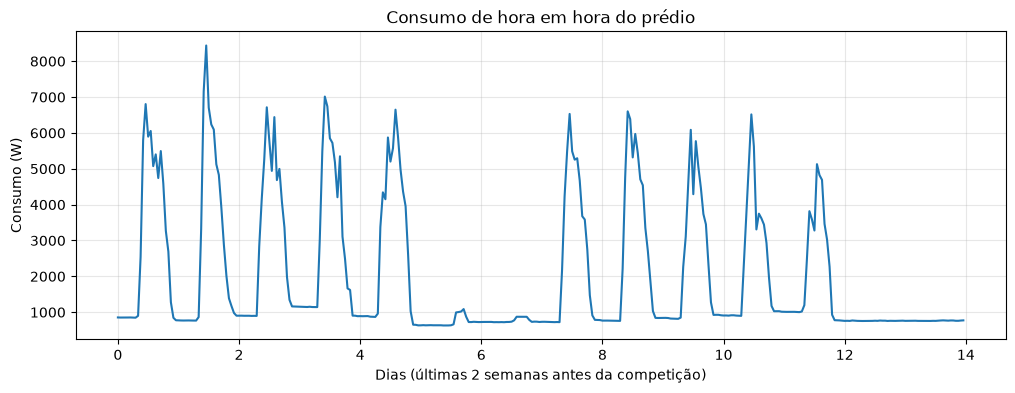

In [2]:
# --- Nomes mais simples para as colunas, e juntar v1 + v2 numa tabela só ---
colunas = ['hora', 'consumo', 'tensao', 'corrente', 'geracao', 'temperatura']
v1.columns = colunas
v2.columns = colunas
dados = pd.concat([v1, v2], ignore_index=True)

# --- Defeitos ---
falha = dados['tensao'] == 0
print('Leituras com tensão 0 (medidor desligado):', falha.sum())
print('  ...e nelas o consumo é 0?', (dados.loc[falha, 'consumo'] == 0).all())
temp_zero = (dados['temperatura'] == 0) & ~falha
print('Temperatura exatamente 0 com medidor ligado:', temp_zero.sum())

# --- Marcar defeitos como "vazio" (NaN) para não entrarem na média ---
consumo = dados['consumo'].astype(float).where(~falha).values
temperatura = dados['temperatura'].astype(float).where(~falha & ~temp_zero).values

# --- De 5 em 5 minutos para de hora em hora: média de cada grupo de 12 leituras ---
consumo_h = np.nanmean(consumo.reshape(-1, 12), axis=1)
temp_h = np.nanmean(temperatura.reshape(-1, 12), axis=1)
print('Horas sem nenhuma leitura boa:', np.isnan(consumo_h).sum())

# --- Horas totalmente vazias: preencher pela "reta entre vizinhos" (interpolação!) ---
pos = np.arange(len(consumo_h))
consumo_h = np.interp(pos, pos[~np.isnan(consumo_h)], consumo_h[~np.isnan(consumo_h)])
temp_h = np.interp(pos, pos[~np.isnan(temp_h)], temp_h[~np.isnan(temp_h)])

# --- Organizar como tabela: uma linha por dia, 24 colunas (uma por hora) ---
n_dias = len(consumo_h) // 24
C = consumo_h.reshape(n_dias, 24)
T = temp_h.reshape(n_dias, 24)
print('Tabela final:', C.shape, '(dias, horas)')

# --- Olhar as últimas 2 semanas ---
plt.figure(figsize=(12, 4))
plt.plot(np.arange(14 * 24) / 24, consumo_h[-14 * 24:])
plt.xlabel('Dias (últimas 2 semanas antes da competição)')
plt.ylabel('Consumo (W)')
plt.title('Consumo de hora em hora do prédio')
plt.grid(True, alpha=0.3)
plt.show()

Consumo médio dos últimos 14 dias (W): [2873 2841 2802 2889 2794  730  762 2487 2645 2366 2283 2076  760  762]

Consumo médio por dia da semana (conferência):
  Seg: 2172 W
  Ter: 2227 W
  Qua: 2205 W
  Qui: 2233 W
  Sex: 2185 W
  Sáb: 1332 W
  Dom: 1345 W


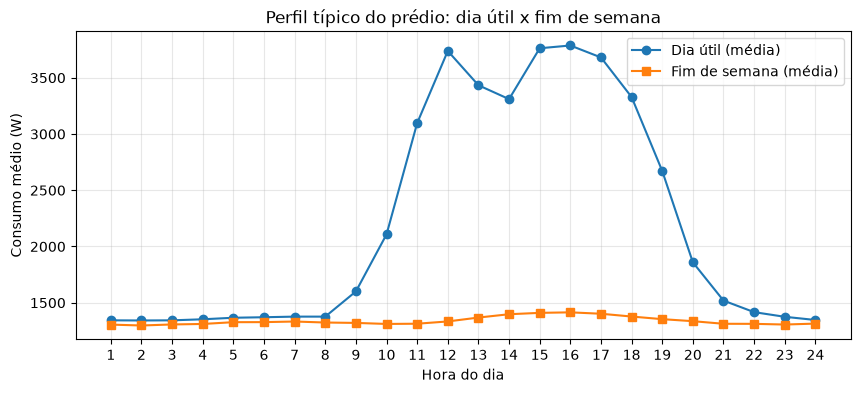

In [3]:
# --- Consumo médio de cada dia ---
media_dia = C.mean(axis=1)
print('Consumo médio dos últimos 14 dias (W):', np.round(media_dia[-14:]).astype(int))

# --- Dia da semana: o último dia dos dados é um DOMINGO ---
# código: 0 = segunda, 1 = terça, ..., 5 = sábado, 6 = domingo
dia_semana = (np.arange(n_dias) - (n_dias - 1) + 6) % 7

nomes = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
print('\nConsumo médio por dia da semana (conferência):')
for k in range(7):
    print(f'  {nomes[k]}: {media_dia[dia_semana == k].mean():.0f} W')

# --- Como é um dia útil típico x um fim de semana típico, hora a hora ---
util = dia_semana < 5                      # segunda a sexta
horas = np.arange(1, 25)                   # 1h, 2h, ..., 24h
plt.figure(figsize=(10, 4))
plt.plot(horas, C[util].mean(axis=0), 'o-', label='Dia útil (média)')
plt.plot(horas, C[~util].mean(axis=0), 's-', label='Fim de semana (média)')
plt.xlabel('Hora do dia')
plt.ylabel('Consumo médio (W)')
plt.title('Perfil típico do prédio: dia útil x fim de semana')
plt.xticks(horas)
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('../figuras/../figuras/comp_perfil_tipico.png', dpi=150, bbox_inches='tight')
plt.show()

In [4]:
# --- A régua da competição: RMSE (erro típico, em W) ---
def rmse(previsto, real):
    return np.sqrt(np.mean((previsto - real)**2))

# --- Os métodos. Todos recebem: o histórico (C, T, dia_semana) e a previsão do tempo de amanhã ---
def ingenuo(C, T, ds, temp_amanha):
    return C[-7]                                    # o mesmo dia da semana passada

def perfil_medio(C, T, ds, temp_amanha, N=5):
    uteis = np.where(ds < 5)[0][-N:]                # posições dos últimos N dias úteis
    return C[uteis].mean(axis=0)                    # média de cada hora

def regressao_temp(C, T, ds, temp_amanha, N=30, lam=1.0):
    uteis = np.where(ds < 5)[0][-N:]                # últimos 30 dias úteis
    H = np.tile(np.eye(24), (len(uteis), 1))        # coluna "sim/não" para cada hora
    temp = T[uteis].reshape(-1)
    X = np.column_stack([H, H * temp[:, None]])     # para cada hora: ponto de partida + inclinação x temperatura
    y = C[uteis].reshape(-1)
    theta = np.linalg.solve(X.T @ X + lam * np.eye(48), X.T @ y)       # equações normais + multa
    X_amanha = np.column_stack([np.eye(24), np.eye(24) * temp_amanha[:, None]])
    return X_amanha @ theta

metodos = [('A. Ingênuo: igual à semana passada',        ingenuo),
           ('B. Perfil médio (últimos 5 dias úteis)',    lambda *a: perfil_medio(*a, N=5)),
           ('B. Perfil médio (últimos 10 dias úteis)',   lambda *a: perfil_medio(*a, N=10)),
           ('B. Perfil médio (últimos 20 dias úteis)',   lambda *a: perfil_medio(*a, N=20)),
           ('C. Regressão hora + temperatura (30 dias)', regressao_temp)]

# --- Prova "andando no tempo": os dias úteis das últimas 4 semanas ---
dias_prova = [i for i in range(n_dias - 28, n_dias) if dia_semana[i] < 5]
print('Dias úteis usados como prova:', len(dias_prova))

print('\nMétodo                                     | RMSE médio na prova (W)')
print('-' * 68)
for nome, metodo in metodos:
    erros = []
    for i in dias_prova:
        previsto = metodo(C[:i], T[:i], dia_semana[:i], T[i])   # só enxerga os dias ANTES do dia i
        erros.append(rmse(previsto, C[i]))
    print(f'{nome:42s} | {np.mean(erros):8.0f}')

Dias úteis usados como prova: 20

Método                                     | RMSE médio na prova (W)
--------------------------------------------------------------------
A. Ingênuo: igual à semana passada         |      964
B. Perfil médio (últimos 5 dias úteis)     |      716
B. Perfil médio (últimos 10 dias úteis)    |      735
B. Perfil médio (últimos 20 dias úteis)    |      985
C. Regressão hora + temperatura (30 dias)  |     1053


Método                                     | Dia 1 | Dia 2 | Dia 3 | Média | Tempo/dia
--------------------------------------------------------------------------------------------
A. Ingênuo: igual à semana passada         |  1166 |  1393 |   731 |  1097 | 0.00 ms
B. Perfil médio (últimos 5 dias úteis)     |  1282 |  1280 |   629 |  1064 | 0.02 ms
B. Perfil médio (últimos 10 dias úteis)    |  1056 |  1239 |   800 |  1032 | 0.01 ms
B. Perfil médio (últimos 20 dias úteis)    |   950 |  1202 |   813 |   988 | 0.01 ms
C. Regressão hora + temperatura (30 dias)  |  1561 |  1303 |   667 |  1177 | 0.29 ms


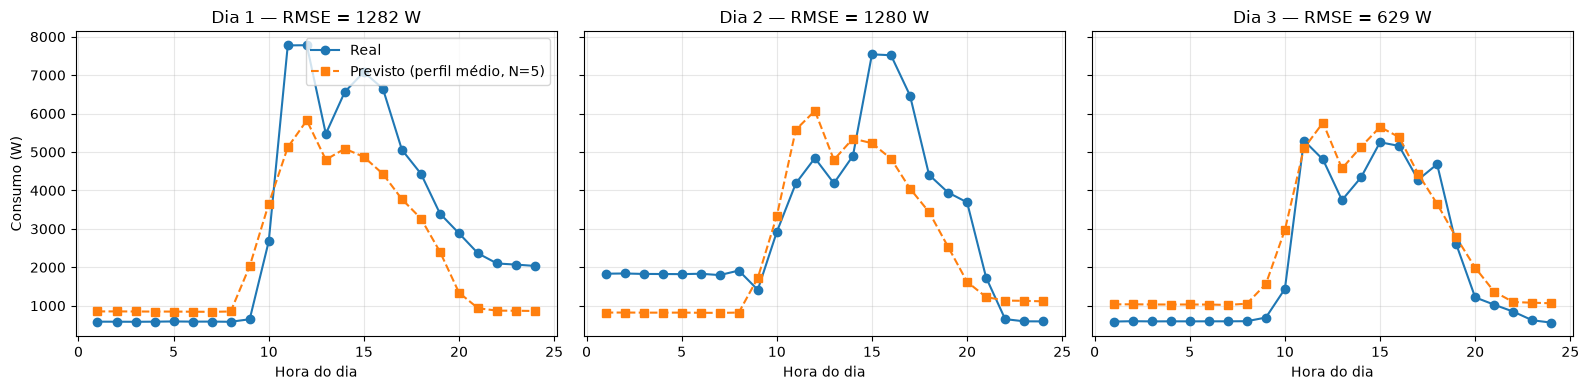


Arquivo "previsoes_competicao.xlsx" salvo. Primeiras linhas:
    hora  dia 1  dia 2  dia 3  dia 4  dia 5
0  01:00    851    822   1035    985    985
1  02:00    852    822   1037    988    988
2  03:00    850    820   1032    983    983
3  04:00    848    819   1031    986    986
4  05:00    848    821   1032    986    986


In [5]:
# --- Gabaritos (dias 1-3) e previsões do tempo (dias 1-5) ---
reais = [abrir(f'v4.{k}.2').iloc[:, 1].values.astype(float) for k in (1, 2, 3)]
previsao_tempo = [abrir(f'v4.{k}.1').iloc[:, 1].values.astype(float) for k in (1, 2, 3, 4, 5)]

# --- Simular a semana: prevê o dia, depois "recebe" o real e acrescenta no histórico ---
def rodar_semana(metodo):
    C_hist, T_hist, ds_hist = C.copy(), T.copy(), dia_semana.copy()
    previsoes, tempos = [], []
    for k in range(5):                                         # dias 1 a 5 (segunda a sexta)
        inicio = time.perf_counter()
        prev = metodo(C_hist, T_hist, ds_hist, previsao_tempo[k])
        tempos.append(time.perf_counter() - inicio)            # tempo de execução da previsão
        previsoes.append(prev)
        if k < 3:                                              # só há consumo real liberado dos dias 1 a 3
            C_hist = np.vstack([C_hist, reais[k]])
            T_hist = np.vstack([T_hist, previsao_tempo[k]])
            ds_hist = np.append(ds_hist, k)                    # 0 = segunda, 1 = terça, 2 = quarta
    return previsoes, tempos

print('Método                                     | Dia 1 | Dia 2 | Dia 3 | Média | Tempo/dia')
print('-' * 92)
resultados = {}
for nome, metodo in metodos:
    prev, tempos = rodar_semana(metodo)
    erros = [rmse(prev[k], reais[k]) for k in range(3)]
    resultados[nome] = prev
    print(f'{nome:42s} | {erros[0]:5.0f} | {erros[1]:5.0f} | {erros[2]:5.0f} | {np.mean(erros):5.0f} '
          f'| {np.mean(tempos) * 1000:.2f} ms')

# --- Gráfico: real x previsto (método escolhido pela prova) ---
escolhido = 'B. Perfil médio (últimos 5 dias úteis)'
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for k in range(3):
    axes[k].plot(horas, reais[k], 'o-', label='Real')
    axes[k].plot(horas, resultados[escolhido][k], 's--', label='Previsto (perfil médio, N=5)')
    axes[k].set_title(f'Dia {k + 1} — RMSE = {rmse(resultados[escolhido][k], reais[k]):.0f} W')
    axes[k].set_xlabel('Hora do dia')
    axes[k].grid(True, alpha=0.3)
axes[0].set_ylabel('Consumo (W)')
axes[0].legend()
plt.tight_layout()
plt.savefig('../figuras/comp_real_vs_previsto.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Arquivo de envio: 24 valores por dia, 5 dias ---
envio = pd.DataFrame({'hora': [f'{h:02d}:00' for h in horas]})
for k in range(5):
    envio[f'dia {k + 1}'] = np.round(resultados[escolhido][k]).astype(int)
envio.to_excel('../resultados/previsoes_competicao.xlsx', index=False)
print('\nArquivo "previsoes_competicao.xlsx" salvo. Primeiras linhas:')
print(envio.head())